# Optimizing the Structure

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch2B-optimizing.ipynb)
:::


In [24]:
#| label: setup
#| tags: [remove-cell, remove-stdout]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import rdkit
except ImportError:
    !pip -q install rdkit
    import rdkit

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    plt.style.use("styles/tufte.mplstyle")
    nproc = 4          # my own computer limit: 4 threads. Yours may vary. Adjust this number to your system's capabilities. Don't include efficiency cores as they are not well-suited for Psi4 calculations.

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output/ch2/2B-optimizing")
output_dir.mkdir(exist_ok=True)


# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
psi4.set_memory("2 GB")

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

**Water** is a small molecule and is a great way to **start** exploring *Psi4*. In the [previous notebook](ch2A-water.ipynb), we demonstrated how to enter an **initial structure** into *Psi4* to create a molecule object. We then applied an **energy calculation** to that object. In this notebook we will feed that molecule object into an **optimization** function that will change the structure as it seeks the **lowest energy**. The result will be a changed object that contains the **new** geometry and other information.

````{note} The Invisible Code
:class: dropdown
There is a **block** of code **at the top** if each notebook that is **invisible** in this web book. When **running** the notebook in *Colab* or on your own computer, that cell will be visible and needs to be the **first** block **executed**. This setup block at the top of each notebook **sets the resources** that *Psi4* may use. It will sense the environment and, if you are using *Colab*, the code will **install** required *Python* tools. On your own computer you will have set up your *Python* environment in advance according to the [setup instructions](ch1-setup.md).

In this notebook, the hidden code also decalres the **destination** for all output file (`output/ch2/2B-optimize`), sets the **number of processors** to use (2 for *Colab*, 4 for my own computer), and sets **flags** that affect many different cells in the notebook. Here, the flag `INTERACTIVE = False` will make all moelcular images render as **still images**. If you set `INTERACTIVE = True`, then those images will be 3-dimensional **interactive objects** that you can spin around and observe at any angle. The interactive images can be very, **very large** when they include molecular orbitals and other objects. The web book is executed with `INTERACTIVE = False` so that I **don't break** the cloud provider that is serving these pages. You can set it to `True` when running your calculation in *Colab* or on your own machine.
````

The energy of a molecule depends on where its nuclei are positioned. An energy calculation determines that energy, but can also be used to determine the **potential energy surface** that the current geometry sits within. If we are not at the perfect bottom of the energy surface then we are sitting on a **slope**, described by the **first derivative** of that surface (real computational chemists love calculus, we will never use it in my course). A **geometry optimization** moves the atoms position according to the **slope** on this potential energy surface until it reaches a minimum: the structure where all the forces on the atoms are zero.

## What You Will Learn
- What a **potential energy surface** looks like for one coordinate.
- How to run `psi4.optimize()` and follow its progress step by step.
- What the **convergence criteria** mean and how to tighten them.
- Why the coordinate system used by the **optimizer** matters.
- How to produce a **two-dimensional** energy surface to visualize the optimization **path**.

## A One Dimensional Energy Surface

The **structures** that we have previously used for water are already very **close** to the minimum energy. Let us **calculate** the energy for a series of structures that we will input using the literature **bond angle** of 104.478° {cite:p}`cccbdb` and vary the **bond length** for the O–H bonds. We are setting a single length for the two bonds and calculating the energy of each structure. This is a **rigid scan**: nothing else is allowed to relax. The [code below](#rigid-scan) will create many different input structures, calculate the energies, and then make a plot of energy vs bond distance.

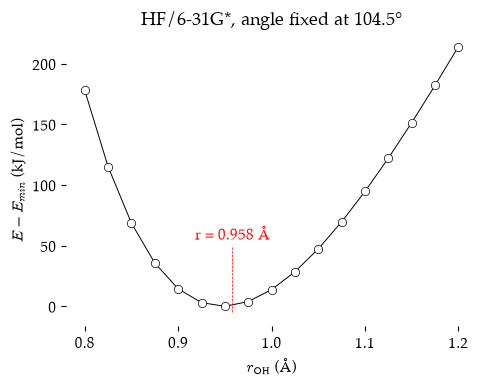

Lowest point of this scan: r = 0.950 Å


In [25]:
#| label: rigid-scan
#| class: scroll-input

# set up Psi4 options and settings
psi4.set_output_file(output_dir / "02B-opt-scan.out", False) # all output files written to the output folder, but not printed to the notebook
psi4.set_options({"reference": "rhf",     # rhf (default), uhf, rohf, or cuhf
                  "scf_type": "pk"})       # SCF algorithm; the Psi4 default is "df"

# set up a list of values for the O-H bond length to scan over
distances = np.arange(0.80, 1.21, 0.025) # create an array of distances from 0.80 to 1.20 Å in increments of 0.025 Å
energies = []                            # create an empty list to store the energies of the molecule at each distance

# Loop over the distances and compute the energy of the molecule at each distance
for r in distances:                      # loop over the distances in the array
    mol = psi4.geometry(f"""
    0 1
    O
    H 1 {r}                              # the r variable is inserted into the string here, so the O-H bond length is set to r
    H 1 {r} 2 104.5
    """)
    E = psi4.energy("hf/6-31g*",         # compute the energy of the molecule at this geometry using the HF method and the 6-31G* basis set
                    molecule=mol)        # use the molecule object we just created
    energies.append(E)                   # append the energy to the energies list

# process the energies to get relative energies in kJ/mol
energies = np.array(energies)            # convert the energies list to a numpy array for easier manipulation
rel_energies = (energies - energies.min()) * psi4.constants.hartree2kJmol  # convert the energies to relative energies in kJ/mol by subtracting the minimum energy and converting from Hartree to kJ/mol

# Plot the results
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(distances, rel_energies, 
        color="black", linewidth=0.7, 
        marker="o", markerfacecolor="white", 
        markeredgecolor="black", markeredgewidth=0.5)
# add styling to the plot
ax.vlines(0.958,-5,50, color="red", linestyle="--", linewidth=0.5)
ax.text(0.958-0.04, 55, f"r = 0.958 Å", color="red")
ax.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax.set_ylabel(r"$E - E_{min}$ (kJ/mol)")
ax.set_title("HF/6-31G*, angle fixed at 104.5°")
# save the plot as an image and display the plot
plt.savefig(output_dir / "02B-opt-scan.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Lowest point of this scan: r = {distances[energies.argmin()]:.3f} Å")

```{note} Why HF/6-31G* here?
:class: dropdown
`hf` with `6-31g*` (also written 6-31G(d)) is a classic **low-cost** combination. The `*` adds *d* functions on oxygen, which let the **electron density** bend away from the atom; without them the H–O–H angle of water comes out several degrees too large. HF/6-31G* geometries are usually within about 0.02 Å and 2° of **experiment** for simple organic molecules.

*Alternatives:* `b3lyp/6-31g*` **costs** a little **more** and is usually **closer** to experiment for bond lengths; `hf/cc-pvdz` is similar in cost and quality to HF/6-31G*. The [next notebook](ch2C-level-of-effort.ipynb) **compares** several choices.
```
We can see that the **literature value** for the O–H bond length ($r = 0.958 \text{Å}$) is not quite the lowest energy point **as calculated** by the HF/6-31G* method. When we **optimize** the geometry, I expect to see **changes** in both the initial bond lengths and angle as the math **seeks** the lowest energy using this very low level method.

## Optimizing a Structure

In the [previous notebook](ch2A-water.ipynb) we used structures for water that we **very close** to or copied directly from the literature values. Now, let us start from an **approximate** structure. We don't necessarily have the **exact** geometry for water memorized, but we know **ballpark** values for bond lengths and angles. Let's just take a **guess** and make the optimizer do the work.

A bond **length** of $1.0 \text{Å}$ and a bond **angle** of $109\degree$ seem appropriate for an $sp^3$ hybridized system with bonds to hydrogen atoms. The [code below](#optimize) uses that as an initial geometry.

```{note} Psi4 settings in this cell
:class: dropdown
`psi4.optimize("hf", ..., return_history=True)`
: Runs the optimization with the *optking* optimizer and also returns a dictionary with the energy, gradient and coordinates of every step. `return_wfn=True` also returns the final wavefunction (orbitals, properties), which we use in later notebooks.

`g_convergence` (not set, so the default `"qchem"` is used)
: The test for "close enough to the minimum". The default stops when the largest force is below $3\times10^{-4}$ hartree/bohr **and** either the energy change is below $10^{-6}$ hartree or the largest step is below $1.2\times10^{-3}$ bohr. This is good enough for structures and energies.
: *Alternatives:* `"gau"` (the *Gaussian* program's criteria, similar), `"gau_tight"` or `"gau_verytight"` (use before a frequency calculation on a floppy molecule or for very accurate structures), `"cfour"`, `"nwchem_loose"`.

`geom_maxiter` (default 50)
: The maximum number of optimization steps. Water converges in a handful; raise it for floppy molecules.
```

In [26]:
#| label: optimize
#| class: scroll-input

# define the geometry of a water molecule in Z-matrix format
water = """
0 1                  # charge and multiplicity: 0 = neutral, 1 = singlet
H
O 1 1.0              # typical bond length for X-H bonds is 1.0 Å
H 2 1.0 1 109.0      # typical bond angle for sp3 is 109.0°
"""

mol = psi4.geometry(water)  # create a molecule object from the water geometry

print(f"Start:  r = {ph.bond_length(mol, 1, 2):.4f} Å\
      angle = {ph.bond_angle(mol, 3, 2, 1):.2f}°")

# optimize geometry and return the optimized energy, wavefunction, and optimization history
E_opt, wfn, history = psi4.optimize("hf/6-31g*",        
                                    molecule=mol, 
                                    return_wfn=True, 
                                    return_history=True
                                    )
print(f"Final:  r = {ph.bond_length(mol, 1, 2):.4f} Å     angle = {ph.bond_angle(mol, 3, 2, 1):.2f}°")
print(f"Final energy = {E_opt:.8f} hartree after {len(history['energy'])} steps")


Start:  r = 1.0000 Å      angle = 109.00°
Optimizer: Optimization complete!
Final:  r = 0.9472 Å     angle = 105.49°
Final energy = -76.01074647 hartree after 4 steps


### The Optimized Molecule

We can **query** the molecule object using the helper functions as shown in the [code block above](#optimize). Because we **input** the original geometry as a **Z-matrix**, we can ask for the text string that describes the Z-matrix within the molecule object. The molecule object is **changed** by the optimizer and the Z-matrix describes the **new optimized geometry**. We can see the bond **lengths** and **angles** directly in the Z-matrix this way. The [code below](z-matrix-extract) will **extract** the text string that describes the molecule, in this case it is a Z-matrix. If we had input the geomtry using Cartesian coordinates, the string would be in that *xyz* format.

In [ ]:
#| label: z-matrix-extract

print("Z-matrix: \n")
print(mol.create_psi4_string_from_molecule())  # print the Z-matrix 

Z-matrix: 

    units Angstrom
    0 1
    --
    0 1
    H           
    O                 1    0.9471986698
    H                 2    0.9471986698      1  105.4933340705




### Investigating the Results

The molecule object `water` has been **updated in place**: it now holds the optimized structure and more information, like the full **history** of all changes. We can view inside the history object that was returned by the `psi4.optimize()` function. After the *Python* command [below](#display-history), the output will show a **dictionary** that contains three named items: energy, gradient and coordinates (scroll through it to view it all). In each is a list of **results**, result at each step in the optimization. We can see the energy and the coordinates at each step.

In [28]:
#| label: display-history
#| class: scroll-output
display(history)

{'energy': [-76.00474277958313,
  -76.01059504136559,
  -76.0107449882576,
  -76.01074647453075],
 'gradient': [array([ 0.00000000,  0.04736920, -0.02313303,  0.00000000, -0.00000000,
          0.04626606,  0.00000000, -0.04736920, -0.02313303]),
  array([ 0.00000000, -0.00641755,  0.00006649,  0.00000000,  0.00000000,
         -0.00013299,  0.00000000,  0.00641755,  0.00006649]),
  array([ 0.00000000,  0.00078587, -0.00022379,  0.00000000, -0.00000000,
          0.00044758,  0.00000000, -0.00078587, -0.00022379]),
  array([ 0.00000000, -0.00012377,  0.00007005,  0.00000000,  0.00000000,
         -0.00014010,  0.00000000,  0.00012377,  0.00007005])],
 'coordinates': [array([[ 0.00000000,  1.53845536, -0.97455757],
         [ 0.00000000,  0.00000000,  0.12281197],
         [ 0.00000000, -1.53845536, -0.97455757]]),
  array([[ 0.00000000,  1.40117509, -0.97994580],
         [ 0.00000000,  0.00000000,  0.12349099],
         [ 0.00000000, -1.40117509, -0.97994580]]),
  array([[ 0.00000000,

Let us plot the energy at each step using the `ph.plot_history()` helper function.

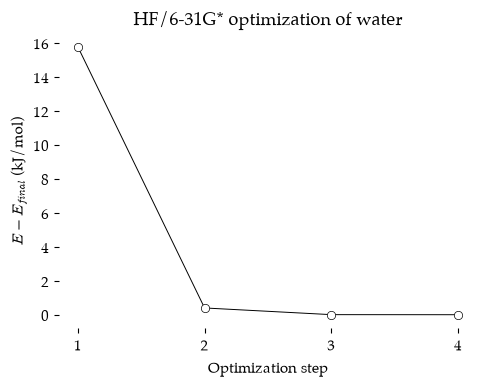

In [29]:
#| label: plot-history

ph.plot_history(history, "HF/6-31G* optimization of water")

The **first step** drops the energy by over 100 kJ/mol; the **last few steps** change it by much less than 1 kJ/mol. The optimizer **stops** when the changes become very small, not when they are exactly zero.

### Watching the Optimization

The history contains the coordinates of each step (in bohr). The [code below](#show-history) will produce an animation of every step that you can rotate with the mouse. Observe the use of the helper function `ph.history_to_xyz`, which will convert the *xyz* data from units of Bohr to Angstroms. The `ph.show_frames()` function will display a list of *xyz* moleculare geometries in a repeating loop. Change the flag `INTERACTIVE = False` to display a set of still images instead. 

In [30]:
#| label: show-history

history_in_Angstroms = ph.history_to_xyz(mol, history) # data was in Bohr, convert to Angstroms for display
ph.show_frames(history_in_Angstroms, 
               interactive=INTERACTIVE, 
               interval=200)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

```{important} An optimized structure is not proven to be a minimum
An optimizer stops wherever the forces vanish. That can be a **minimum**, a local minimum, or a **saddle point** (a transition state). For example, if we started from an exactly linear water molecule, symmetry would keep it linear and the optimizer would happily "converge" there. The way to check is a **frequency calculation**: a minimum has no imaginary frequencies. We do that in the [Vibrations notebook](ch2D-vibrations.ipynb).
```

## Summary
- An **optimization** follows the **gradient** downhill on the potential **energy** surface.
- `return_history=True` lets us plot the **progress** and look at the structure at **each step**.

```{warning} AI Statement
:class: dropdown
This
```

### A Two-Dimensional Energy Surface

Earlier we [scanned one coordinate](#rigid-scan) with the angle held fixed. Water has three internal coordinates, but because both O–H bonds stay equal during this optimization, we can describe every step with just **two**: the O–H **bond length** and the H–O–H **bond angle**. The [code below](#scan-2d) calculates the energy on a **grid** of lengths and angles (399 single-point energies, about a minute), which maps out the **potential energy well**. The [next cell](#plot-2d) draws the surface in 3D and as a contour map, and adds the **path** the optimizer took, using the coordinates saved in `history`.

```{note} Psi4 settings in this cell
:class: dropdown
`E_grid[i, j]`
: A 2D *NumPy* array: each row is one angle and each column is one bond length. All energies are made relative to the optimized energy `E_opt`, so the bottom of the well is close to zero.
```

In [31]:
#| label: scan-2d
#| class: scroll-input

psi4.set_output_file(output_dir / "02B-opt-2Dscan.out", False)  # write output to a file, not the notebook

r_values     = np.linspace(0.91, 1.01, 41)    # O-H bond lengths from 0.88 to 1.06 Å
angle_values = np.linspace(98.0, 114.0, 33)     # H-O-H angles from 96 to 116°

E_grid = np.zeros((len(angle_values), len(r_values)))   # rows = angles, columns = distances

for i, angle in enumerate(angle_values):        # loop over the angles...
    for j, r in enumerate(r_values):            # ...and, for each angle, over the distances
        scan_mol = psi4.geometry(f"""
        0 1
        H
        O 1 {r}
        H 2 {r} 1 {angle}
        """)
        E_grid[i, j] = psi4.energy("hf/6-31g*", molecule=scan_mol)

# relative energies in kJ/mol, measured from the optimized structure
rel_E_grid = (E_grid - E_opt) * psi4.constants.hartree2kJmol
print(f"{E_grid.size} energies calculated")

1353 energies calculated


In [ ]:
#| label: calc-path
#| class: scroll-input

# bond length and angle at each optimization step (history coordinates are in bohr)
path_r, path_angle = [], []
for coords in history["coordinates"]:
    xyz = np.asarray(coords) * psi4.constants.bohr2angstroms
    v1 = xyz[0] - xyz[1]                      # O -> H1  (atom order is H, O, H)
    v2 = xyz[2] - xyz[1]                      # O -> H2
    r1, r2 = np.linalg.norm(v1), np.linalg.norm(v2)
    path_r.append((r1 + r2) / 2)
    path_angle.append(np.degrees(np.arccos(np.dot(v1, v2) / (r1 * r2))))
path_E = (np.array(history["energy"]) - E_opt) * psi4.constants.hartree2kJmol


step 1: r = 1.0000 Å   angle = 109.00°   E =  15.76 kJ/mol
step 2: r = 0.9438 Å   angle = 103.56°   E =   0.40 kJ/mol
step 3: r = 0.9479 Å   angle = 105.64°   E =   0.00 kJ/mol
step 4: r = 0.9472 Å   angle = 105.49°   E =   0.00 kJ/mol


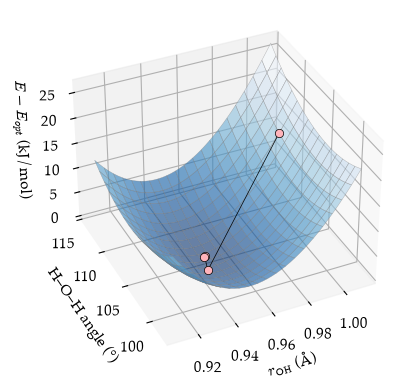

In [37]:
#| label: 3d-plot
#| class: scroll-input

for n, (r, a, e) in enumerate(zip(path_r, path_angle, path_E), start=1):
    print(f"step {n}: r = {r:.4f} Å   angle = {a:6.2f}°   E = {e:6.2f} kJ/mol")

R, A = np.meshgrid(r_values, angle_values)    # 2D grids of x and y values to match E_grid

fig, ax3d = plt.subplots(figsize=(5, 4),
                         subplot_kw={"projection": "3d", 
                                     "computed_zorder": False})
# left: 3D surface with the optimization path on top
ax3d.plot_surface(R, A, rel_E_grid, cmap="Blues_r", alpha=0.6, rstride=2, cstride=2,
                  linewidth=0.3, edgecolor="grey", zorder=1)
ax3d.plot(path_r, path_angle, path_E, color="black", linewidth=0.5, marker="o",
          markerfacecolor="#FFB3BA", markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax3d.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax3d.set_ylabel("H–O–H angle (°)")
ax3d.set_zlabel(r"$E - E_{opt}$ (kJ/mol)")
ax3d.view_init(elev=35, azim=-115)

plt.savefig(output_dir / "02B-opt-3Dscan.png", dpi=300, bbox_inches="tight")


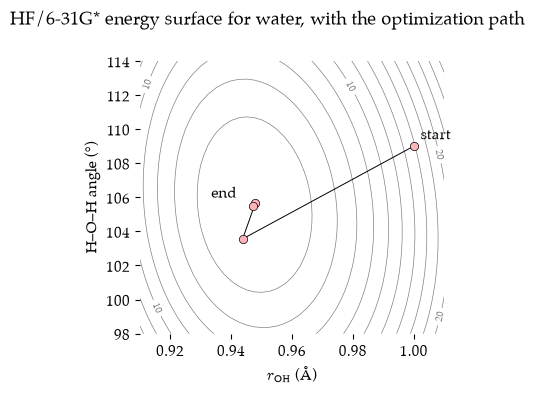

In [ ]:
#| label: 2d-plot
#| class: scroll-input

fig, ax2d = plt.subplots(figsize=(4, 4))

# right: contour map (looking straight down on the surface) with the same path
levels = np.arange(0, rel_E_grid.max(), 2.0)
cs = ax2d.contour(R, A, rel_E_grid, levels=levels, colors="grey", linewidths=0.5, zorder=1)
ax2d.clabel(cs, levels[::5], fontsize=7, fmt="%.0f")
ax2d.plot(path_r, path_angle, color="black", linewidth=0.7, marker="o",
          markerfacecolor="#FFB3BA", markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax2d.annotate("start", (path_r[0], path_angle[0]), xytext=(5, 5), textcoords="offset points")
ax2d.annotate("end", (path_r[-1], path_angle[-1]), xytext=(-30, 6), textcoords="offset points")
ax2d.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax2d.set_ylabel("H–O–H angle (°)")

fig.suptitle("HF/6-31G* energy surface for water, with the optimization path")
plt.savefig(output_dir / "02B-opt-2Dscan.png", dpi=300, bbox_inches="tight")
plt.show()

The first step **overshoots**: it jumps from the start (1.00 Å, 109°) past the bottom of the well, to an angle that is a little too small. The next steps **correct** this and settle at the minimum (0.947 Å, 105.5°). Notice that the well is **steep** along the bond length and **shallow** along the angle. Stretching a bond costs much more energy than bending it by the same proportion.